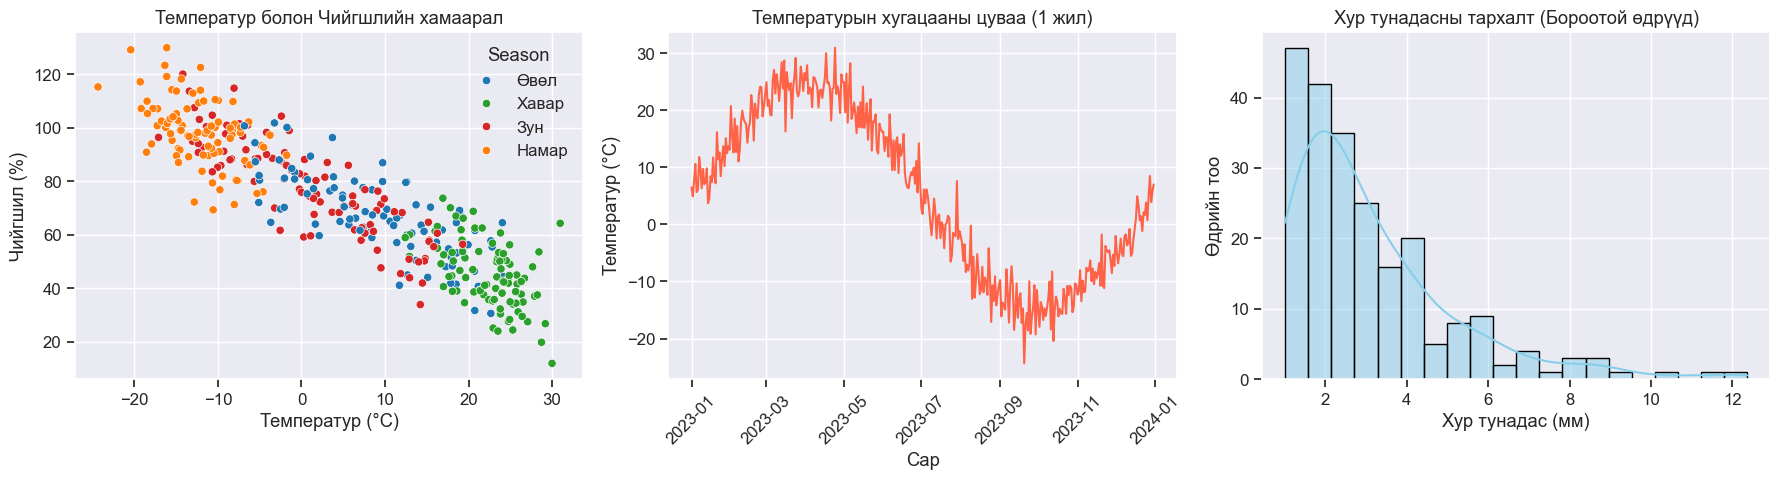

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Бонус оноо авах: Графикийн хэв маягийг мэргэжлийн харагдуулах
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_context("notebook", font_scale=1.1)

# 1. Хуурамч (Dummy) цаг уурын өгөгдөл үүсгэх (1 жил)
np.random.seed(42)
dates = pd.date_range(start='2023-01-01', periods=365)
temp = np.sin(np.linspace(0, 3.14*2, 365)) * 20 + 5 + np.random.normal(0, 3, 365)
humidity = 80 - temp * 1.5 + np.random.normal(0, 10, 365)
precip = np.random.exponential(scale=2, size=365)
precip[precip < 1] = 0 # Бороо ороогүй өдрүүд

df = pd.DataFrame({'Date': dates, 'Temp_C': temp, 'Humidity_%': humidity, 'Precip_mm': precip})
df['Season'] = df['Date'].dt.month % 12 // 3 + 1
df['Season'] = df['Season'].map({1: 'Өвөл', 2: 'Хавар', 3: 'Зун', 4: 'Намар'})

# График зурах хэсэг
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# А. Scatter plot: Температур vs Чийгшил
sns.scatterplot(data=df, x='Temp_C', y='Humidity_%', hue='Season', palette=['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e'], ax=axes[0])
axes[0].set_title('Температур болон Чийгшлийн хамаарал')
axes[0].set_xlabel('Температур (°C)')
axes[0].set_ylabel('Чийгшил (%)')

# Б. Line chart: Температурын цуваа
sns.lineplot(data=df, x='Date', y='Temp_C', color='tomato', ax=axes[1])
axes[1].set_title('Температурын хугацааны цуваа (1 жил)')
axes[1].set_xlabel('Сар')
axes[1].set_ylabel('Температур (°C)')
axes[1].tick_params(axis='x', rotation=45)

# В. Histogram: Хур тунадас
sns.histplot(df[df['Precip_mm'] > 0]['Precip_mm'], bins=20, color='skyblue', kde=True, ax=axes[2])
axes[2].set_title('Хур тунадасны тархалт (Бороотой өдрүүд)')
axes[2].set_xlabel('Хур тунадас (мм)')
axes[2].set_ylabel('Өдрийн тоо')

plt.tight_layout()
plt.show()

## Даалгавар: Өнгө + Хэлбэр + Хэмжээ + Ирмэг (Pre-attentive encoding)

4 төрлийн бараа **(A, B, C, D)** болон 3 улирлын **(Өвөл, Хавар, Зун)** борлуулалтын өгөгдлийг нэг scatter plot-д дүрслэхдээ:

| Харааны суваг | Юуг кодлох | Яагаад |
|---|---|---|
| **Өнгө** | Улирал | Хүйтэн↔дулаан сэтгэлзүйн холбоо |
| **Хэлбэр** | Бараа төрөл | Өнгө харааны бэрхшээлтэй хэрэглэгч ч ялгана |
| **Хэмжээ** | Борлуулалтын дүн | Их = том, бага = жижиг |
| **Ирмэг** | Тодруулга | Давхцсан цэгүүдийг ялгана |

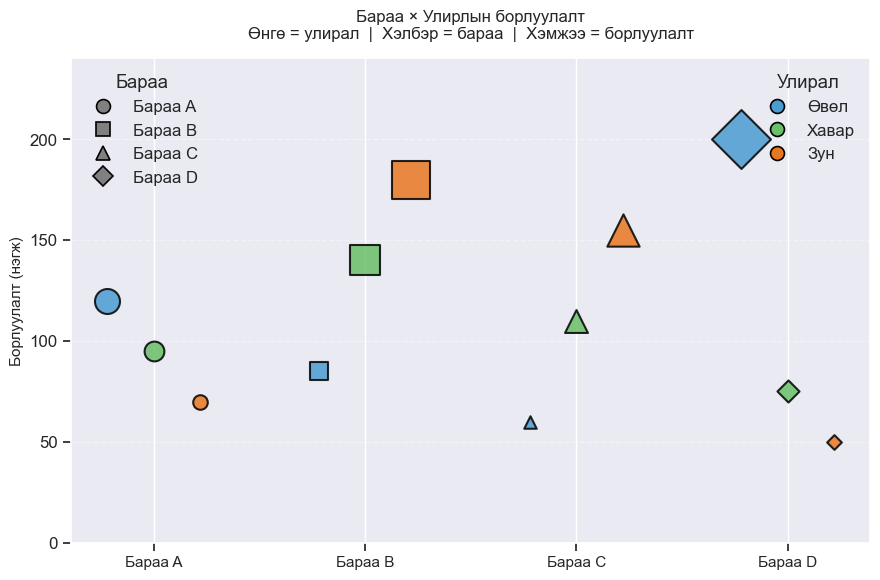

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# ─── 1. Өгөгдөл ───────────────────────────────────────────────────
products = ['A', 'B', 'C', 'D']
seasons  = ['Өвөл', 'Хавар', 'Зун']

sales = {
    'Өвөл':  {'A': 120, 'B': 85,  'C': 60,  'D': 200},
    'Хавар': {'A': 95,  'B': 140, 'C': 110, 'D': 75},
    'Зун':   {'A': 70,  'B': 180, 'C': 155, 'D': 50},
}

# ─── 2. Өнгөний схем (улирал) ─────────────────────────────────────
# Өвөл → цэнхэр (хүйтэн),  Хавар → ногоон (ургалт),  Зун → улбар (халуун)
season_colors = {'Өвөл': '#4B9CD3', 'Хавар': '#6ABF69', 'Зун': '#E87722'}

# ─── 3. Хэлбэрийн сонголт (бараа) ────────────────────────────────
# o тойрог=A,  s дөрвөлжин=B,  ^ гурвалжин=C,  D ромб=D
product_markers = {'A': 'o', 'B': 's', 'C': '^', 'D': 'D'}

# ─── 4. Хэмжээний стратеги ────────────────────────────────────────
# scatter() area ~ r^2  →  sqrt-ээр жигдэлнэ: size = (val/max * 30)^2
def to_size(s):
    return (s / 200 * 30) ** 2

# ─── 5. График ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
x_pos = {'A': 1, 'B': 2, 'C': 3, 'D': 4}

for si, season in enumerate(seasons):
    for prod in products:
        s = sales[season][prod]
        ax.scatter(
            x_pos[prod] + (si - 1) * 0.22,
            s,
            s          = to_size(s),
            c          = season_colors[season],
            marker     = product_markers[prod],
            edgecolors = 'black',   # ирмэг: давхцсан цэг ялгана
            linewidths = 1.5,
            alpha      = 0.85,
            zorder     = 3,
        )

ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Бараа A', 'Бараа B', 'Бараа C', 'Бараа D'], fontsize=11)
ax.set_ylabel('Борлуулалт (нэгж)', fontsize=11)
ax.set_title(
    'Бараа × Улирлын борлуулалт\n'
    'Өнгө = улирал  |  Хэлбэр = бараа  |  Хэмжээ = борлуулалт',
    fontsize=12, pad=14
)
ax.set_ylim(0, 240)
ax.grid(axis='y', linestyle='--', alpha=0.4)

# Тайлбар: улирал
leg1 = ax.legend(
    handles=[
        mlines.Line2D([], [], color=season_colors[s], marker='o',
                      linestyle='None', markersize=10,
                      markeredgecolor='black', markeredgewidth=1.2, label=s)
        for s in seasons
    ],
    title='Улирал', loc='upper right', framealpha=0.9
)
ax.add_artist(leg1)

# Тайлбар: бараа
ax.legend(
    handles=[
        mlines.Line2D([], [], color='gray', marker=product_markers[p],
                      linestyle='None', markersize=10,
                      markeredgecolor='black', markeredgewidth=1.2, label='Бараа ' + p)
        for p in products
    ],
    title='Бараа', loc='upper left', framealpha=0.9
)

plt.tight_layout()
plt.show()

## Шийдвэрийн тайлбар

### Өнгө (улирал)
- **Өвөл → `#4B9CD3` цэнхэр** — хүйтний сэтгэлзүйн холбоо
- **Хавар → `#6ABF69` ногоон** — шинэлэг, ургалтын дохио
- **Зун → `#E87722` улбар шар** — дулаан, идэвхтэй улирал
- 3 өнгө нь тод ялгаатай (qualitative palette), дарааллын утга биш

### Хэлбэр (бараа төрөл)
- `o` тойрог = **A** — энгийн, суурь бараа
- `s` дөрвөлжин = **B** — хоёрдогч бараа
- `^` гурвалжин = **C** — өсөлтийн дохио
- `D` ромб = **D** — онцгой, тусгай бараа
- Өнгөнөөс үл хамааран хэлбэрээр ялгаж болно → өнгө сохорт найрсаг

### Хэмжээ (борлуулалт)
- `size = (утга / 200 × 30)²`
- Matplotlib scatter area нь **r²-д пропорциональ** тул sqrt-аар жигдэлнэ
- Эс тэгвэл 200 vs 100 нь 4 дахин том харагдах байсан (2× биш)

### Ирмэг (`edgecolor='black', linewidth=1.5`)
- Давхцсан цэгүүдийн **хил заагийг** тодорхой харуулна
- `alpha=0.85` + хар ирмэг → давхардсан газарт гүн харагдана
- Жижиг (бага борлуулалт) цэг ч алга болохгүй